In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

sns.set_style("whitegrid")

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)
train.head()

Train shape: (576, 12)
Test shape: (120, 12)


,profile pic,nums/length username,fullname words,nums/length fullname,name==username,description length,external URL,private,#posts,#followers,#follows,fake
0,1,0.27,0,0.0,0,53,0,0,32,1000,955,0
1,1,0.00,2,0.0,0,44,0,0,286,2740,533,0
2,1,0.10,2,0.0,0,0,0,1,13,159,98,0
3,1,0.00,1,0.0,0,82,0,0,679,414,651,0
4,1,0.00,2,0.0,0,0,0,1,6,151,126,0


fake
0    288
1    288
Name: count, dtype: int64


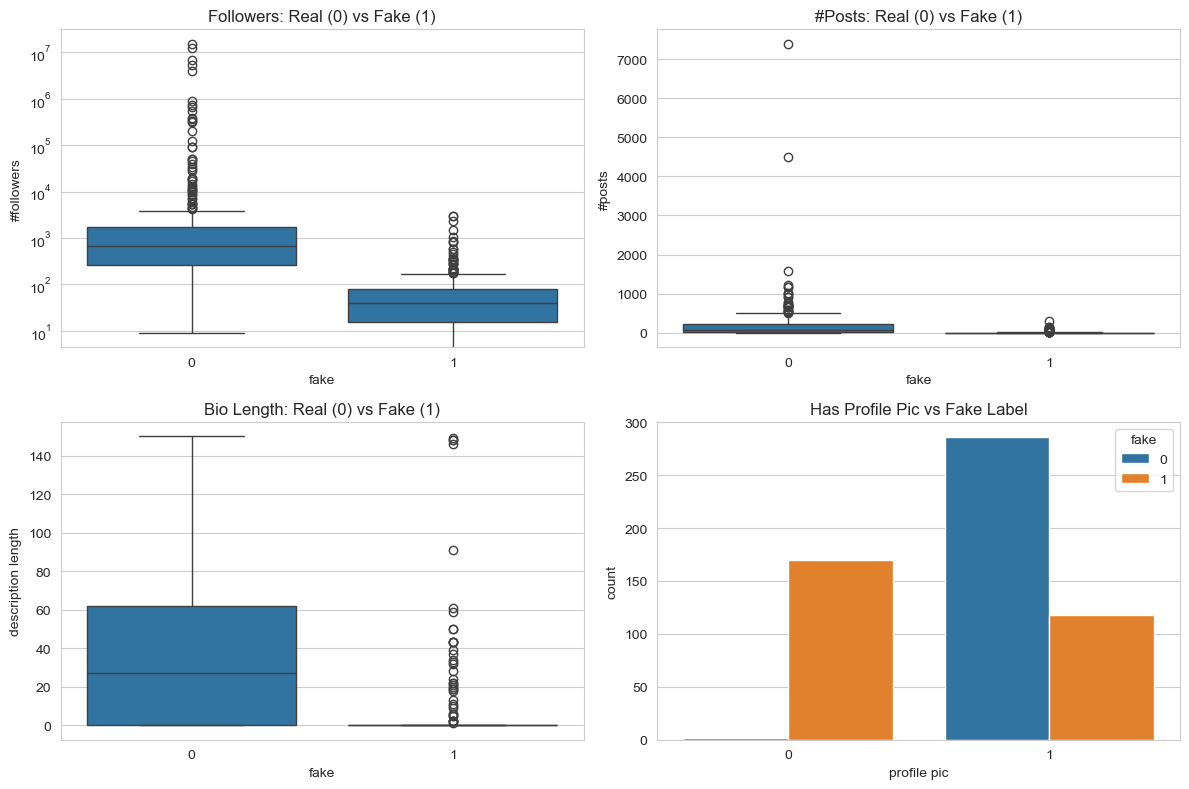

In [3]:
print(train["fake"].value_counts())

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.boxplot(data=train, x="fake", y="#followers", ax=axes[0, 0])
axes[0, 0].set_title("Followers: Real (0) vs Fake (1)")
axes[0, 0].set_yscale("log")

sns.boxplot(data=train, x="fake", y="#posts", ax=axes[0, 1])
axes[0, 1].set_title("#Posts: Real (0) vs Fake (1)")

sns.boxplot(data=train, x="fake", y="description length", ax=axes[1, 0])
axes[1, 0].set_title("Bio Length: Real (0) vs Fake (1)")

sns.countplot(data=train, x="profile pic", hue="fake", ax=axes[1, 1])
axes[1, 1].set_title("Has Profile Pic vs Fake Label")

plt.tight_layout()
plt.savefig("eda_overview.png", dpi=150)
plt.show()

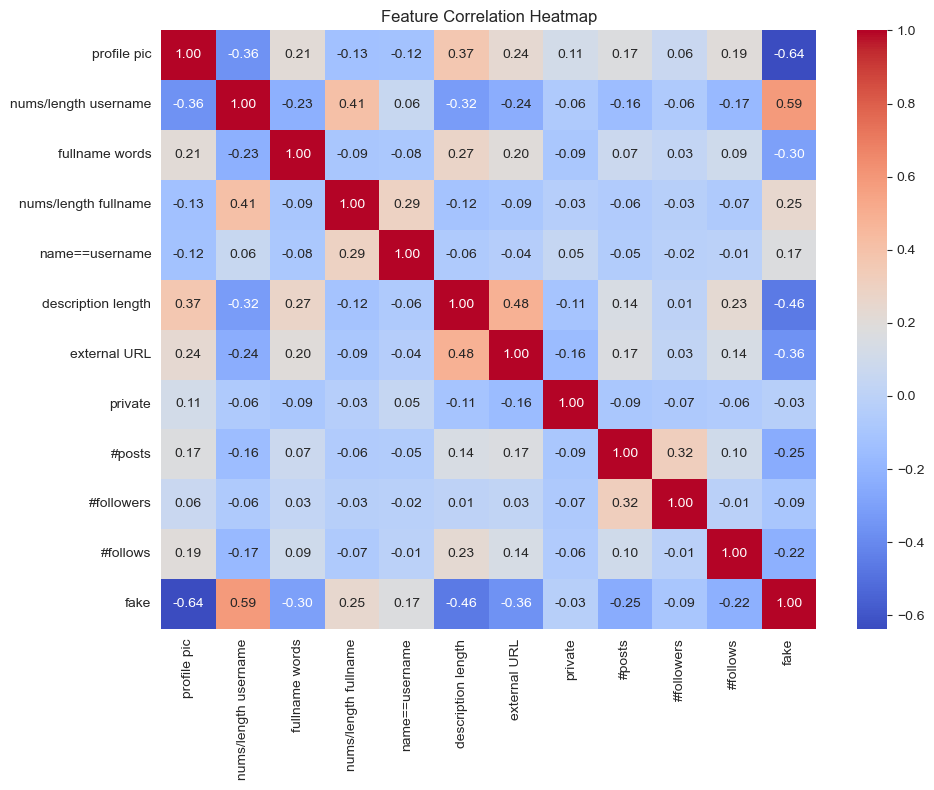

In [4]:
plt.figure(figsize=(10, 8))
sns.heatmap(train.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=150)
plt.show()

In [5]:
X_train = train.drop(columns=["fake"])
y_train = train["fake"]

X_test = test.drop(columns=["fake"])
y_test = test["fake"]

# Scale features (helps KNN and Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

results = []

for name, model in models.items():

    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)

    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-score": round(f1, 4),
    })

    print(f"\n=== {name} ===")
    print(classification_report(y_test, preds, target_names=["Real", "Fake"]))

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
print("\n--- Model Comparison ---")
print(results_df.to_string(index=False))


=== Logistic Regression ===
              precision    recall  f1-score   support

        Real       0.87      0.88      0.88        60
        Fake       0.88      0.87      0.87        60

    accuracy                           0.88       120
   macro avg       0.88      0.88      0.87       120
weighted avg       0.88      0.88      0.87       120


=== KNN (k=5) ===
              precision    recall  f1-score   support

        Real       0.88      0.88      0.88        60
        Fake       0.88      0.88      0.88        60

    accuracy                           0.88       120
   macro avg       0.88      0.88      0.88       120
weighted avg       0.88      0.88      0.88       120


=== Naive Bayes ===
              precision    recall  f1-score   support

        Real       0.93      0.42      0.57        60
        Fake       0.62      0.97      0.76        60

    accuracy                           0.69       120
   macro avg       0.77      0.69      0.67       120
weigh